# 02 — Modelos supervisados + K-Means (E2)
**AppleVision Chile — MLY1101**

> **Leer antes de interpretar los resultados.** Los datos son 38 filas de solo 4 manzanas (ids 4, 8, 9, 10) de un video corto. La etiqueta `apto` viene del semáforo de negocio (sin calibre, porque `px_por_mm` aún no está calibrado), no de una verdad de campo. Para evitar fuga directa, los modelos supervisados **no usan** `hue`, `saturacion` ni `aspecto` (las entradas del semáforo) y se validan con *leave-one-id-out*. Las métricas sirven para demostrar el pipeline, no para decidir nada comercial.

## 1. Datos y etiqueta

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from src.ml.features import preparar, FEATURES_SUPERVISADO, FEATURES_KMEANS, FEATURES_REGLA
from src.ml import train, evaluate
sns.set_theme(style='whitegrid')
FIG = Path('../reports/figuras_ml'); FIG.mkdir(parents=True, exist_ok=True)

df, X, y, grupos = preparar()
print('Features supervisadas:', FEATURES_SUPERVISADO, '| excluidas (regla):', FEATURES_REGLA)
print(pd.crosstab(df['id'], df['semaforo']))
print('Balance apto:', y.value_counts().to_dict())

2026/11/10 17:45:18 INFO mlflow.tracking.fluent: Experiment with name 'applevision-calidad' does not exist. Creating a new experiment.


Features supervisadas: ['area_px', 'diametro_mm_est', 'valor'] | excluidas (regla): ['hue', 'saturacion', 'aspecto']
semaforo  detalle  good  no_pasa
id                              
4              13     0        0
8              11     4        0
9               3     2        1
10              1     3        0
Balance apto: {0: 29, 1: 9}


## 2. Random Forest y XGBoost (validación leave-one-id-out)

In [2]:
modelos = train.crear_modelos(y)
res, preds = {}, {}
for nombre, m in modelos.items():
    preds[nombre] = train.predecir_por_grupos(m, X, y, grupos)
    res[nombre] = evaluate.metricas_clasificacion(y, preds[nombre])
pd.DataFrame(res).T.round(3)

,accuracy,precision,recall,f1
random_forest,0.447,0.125,0.222,0.160
xgboost,0.500,0.083,0.111,0.095


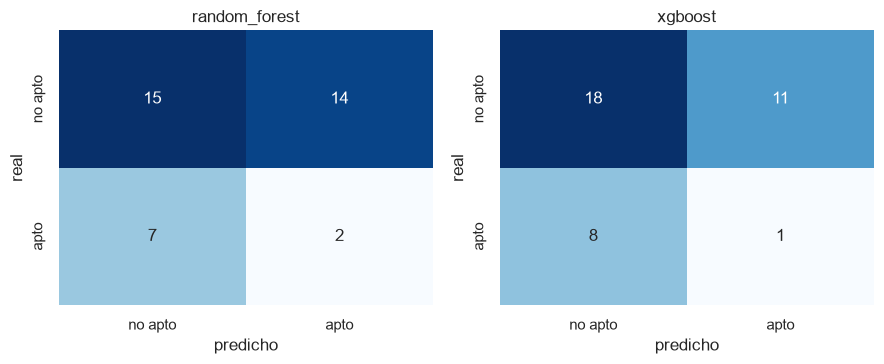

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (nombre, p) in zip(axs, preds.items()):
    sns.heatmap(evaluate.matriz_confusion(y, p), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['no apto', 'apto'], yticklabels=['no apto', 'apto'])
    ax.set_title(nombre); ax.set_xlabel('predicho'); ax.set_ylabel('real')
plt.tight_layout(); plt.savefig(FIG / 'matrices_confusion.png', dpi=120); plt.show()

## 3. Importancia de características
Modelos reajustados con todos los datos (solo para ver importancias y guardar).

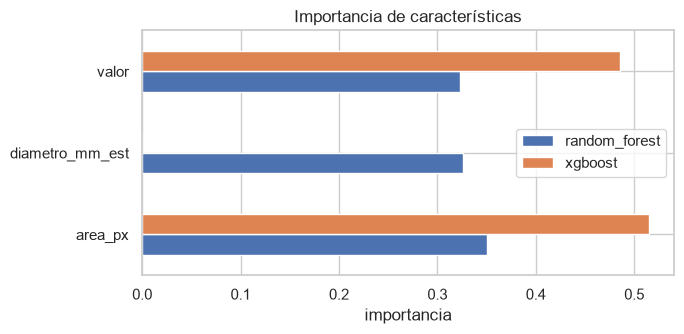

,random_forest,xgboost
area_px,0.351,0.515
diametro_mm_est,0.326,0.000
valor,0.323,0.485


In [4]:
finales = {n: m.fit(X, y) for n, m in train.crear_modelos(y).items()}
imp = pd.DataFrame({n: m.feature_importances_ for n, m in finales.items()}, index=FEATURES_SUPERVISADO)
ax = imp.plot.barh(figsize=(7, 3.5), title='Importancia de características'); ax.set_xlabel('importancia')
plt.tight_layout(); plt.savefig(FIG / 'importancia.png', dpi=120); plt.show()
imp.round(3)

## 4. K-Means (k=3) no supervisado
Sobre geometría y color (sin `area_px`, redundante con el diámetro), estandarizado.

In [5]:
kmeans = train.entrenar_kmeans(df[FEATURES_KMEANS], k=3)
Xs = kmeans[0].transform(df[FEATURES_KMEANS]); df['cluster'] = kmeans[1].labels_
sil = evaluate.silhouette(Xs, df['cluster'])
print(f'Silhouette K-Means (k=3): {sil:.3f}')
print(df['cluster'].value_counts().sort_index().to_dict())
print(df.groupby('cluster')[FEATURES_KMEANS].mean().round(2))
print('Cluster vs id:'); print(pd.crosstab(df['cluster'], df['id']))

Silhouette K-Means (k=3): 0.245
{0: 11, 1: 16, 2: 11}
         diametro_mm_est    hue  saturacion   valor  aspecto
cluster                                                     
0                  41.08  16.35      141.28  169.31     0.81
1                  34.74   9.49      148.04  146.34     0.85
2                  31.08  19.76      132.84  157.32     0.93
Cluster vs id:
id       4   8   9   10
cluster                
0         7   3   0   1
1         5   5   3   3
2         1   7   3   0


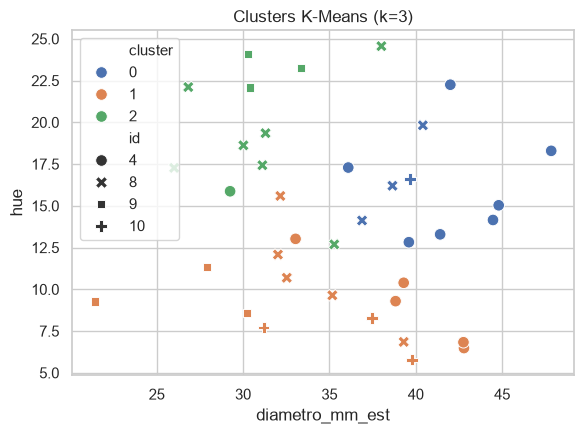

In [6]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.scatterplot(data=df, x='diametro_mm_est', y='hue', hue='cluster', style='id', palette='deep', s=70, ax=ax)
ax.set_title('Clusters K-Means (k=3)'); plt.tight_layout(); plt.savefig(FIG / 'kmeans.png', dpi=120); plt.show()

## 5. Persistencia y MLflow

In [7]:
figs = {'confusion': FIG / 'matrices_confusion.png', 'importancia': FIG / 'importancia.png'}
for nombre, m in finales.items():
    ruta = train.guardar_modelo(m, nombre)
    params = {k: v for k, v in m.get_params().items() if isinstance(v, (int, float, str, bool))}
    evaluate.registrar(nombre, {**params, 'features': ','.join(FEATURES_SUPERVISADO), 'cv': 'leave-one-id-out'},
                       {f'cv_{k}': v for k, v in res[nombre].items()}, figs, ruta)
ruta = train.guardar_modelo(kmeans, 'kmeans_k3')
evaluate.registrar('kmeans_k3', {'k': 3, 'features': ','.join(FEATURES_KMEANS)},
                   {'silhouette': sil}, {'kmeans': FIG / 'kmeans.png'}, ruta)
print(sorted(p.name for p in Path('../models').glob('*.joblib')))

['kmeans_k3.joblib', 'random_forest.joblib', 'xgboost.joblib']


## 6. Conclusiones
- Los resultados de RF/XGBoost deben leerse con mucha cautela: 4 manzanas, validación por id y una etiqueta simulada. Con features que no son las de la regla, el modelo solo aprende relaciones indirectas (brillo y tamaño asociados a color/forma), por lo que un F1 bajo es esperable y honesto; uno alto sería sospechoso.
- El Silhouette de K-Means mide separación de grupos, no calidad comercial. Revisar si los clusters solo reproducen la identidad de cada manzana (tabla cluster vs `id`).
- Antes de modelar en serio: recalibrar `px_por_mm`, capturar más partidas y usar etiquetas reales de Roboflow o de calidad de campo.